# 06 Death risk

This notebook covers research question 3: how the risk of death has changed over time, and whether it is higher for clients or for hired staff.

The unit is one participation in one expedition above base camp, and rates are deaths per 1,000 participations with 95% Wilson intervals. This is not a yearly risk per person: hired staff often work several expeditions per season and spend more time in dangerous zones.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import FEATURES_PATH, PROCESSED_DIR
from src.data_dictionary import parse_guide
from src.death_risk import (TREND_YEARS, age_group, compare_clients_hired, counter_rates, death_class_shares,
                            expedition_counts, experience_group, member_rates, risk_ratio_interval,
                            shared_expeditions)
from src.style import BLUE, GRID, INK, ORANGE, apply_style, save_figure

apply_style()

exped = pd.read_parquet(PROCESSED_DIR / "exped.parquet")
members = pd.read_parquet(PROCESSED_DIR / "members.parquet")
peaks = pd.read_parquet(PROCESSED_DIR / "peaks.parquet")
features = pd.read_parquet(FEATURES_PATH)
season_names = parse_guide()[("exped", "SEASON")]["codes"]
peak_names = peaks.set_index("PEAKID")["PKNAME"].to_dict()

## 1. Trend by decade, 1950-2025

Clients are members on the permit who went above base camp (not `BCONLY`, not `NOTTOBC`), counted from member records. For hired staff we use the expedition counters `HDEATHS / TOTHIRED`, which cover hired staff above base camp, because they appear in `members` only after significant events.

Expeditions 1950-2025: 11,788
Client deaths above base camp: 794 (MDEATHS incl. base camp only: 838)
Expeditions with HDEATHS > TOTHIRED: 14; hired deaths where TOTHIRED = 0: 17
        client_deaths  client_n  client_per_1000  hired_deaths  hired_n  hired_per_1000
DECADE                                                                                 
1950               15       566             26.5             9      753            12.0
1960               22       780             28.2            10      955            10.5
1970               88      3096             28.4            58     2180            26.6
1980              192      8661             22.2            47     3036            15.5
1990              149     11286             13.2            47     3976            11.8
2000              134     15369              8.7            55     7176             7.7
2010              139     16065              8.7            74    10866             6.8
2020               55     1086

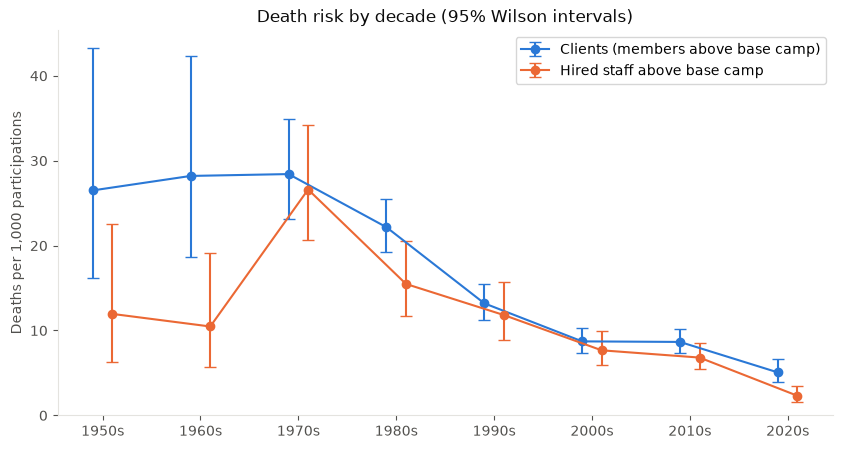

In [2]:
counts = expedition_counts(exped, members, peaks)
print(f"Expeditions {TREND_YEARS[0]}-{TREND_YEARS[1]}: {len(counts):,}")
print(f"Client deaths above base camp: {counts['CLIENT_DEATHS'].sum():,} (MDEATHS incl. base camp only: {int(counts['MDEATHS'].sum()):,})")
print(f"Expeditions with HDEATHS > TOTHIRED: {(counts['HIRED_DEATHS'] > counts['HIRED']).sum()}; "
      f"hired deaths where TOTHIRED = 0: {counts.loc[counts['HIRED'] == 0, 'HIRED_DEATHS'].sum()}")

trend = counter_rates(counts, "DECADE")
print(trend[["client_deaths", "client_n", "client_per_1000", "hired_deaths", "hired_n", "hired_per_1000"]].round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
x = trend.index.to_numpy()
for who, color, label in [("client", BLUE, "Clients (members above base camp)"), ("hired", ORANGE, "Hired staff above base camp")]:
    rate = trend[f"{who}_per_1000"]
    err = [rate - trend[f"{who}_low"], trend[f"{who}_high"] - rate]
    ax.errorbar(x + (-1 if who == "client" else 1), rate, yerr=err, marker="o", capsize=4, color=color, label=label)
ax.set_xticks(x, [f"{d}s" for d in x])
ax.set_ylabel("Deaths per 1,000 participations")
ax.set_title("Death risk by decade (95% Wilson intervals)")
ax.set_ylim(bottom=0)
ax.legend()
save_figure(fig, "06_death_trend.png")
plt.show()

## 2. Risk among clients, 1990-2025

This is the same population as in the main model (`features_v1`). The rates are descriptive: a difference between groups can come from where a group climbs rather than from the group itself. Experienced climbers, for example, may choose harder peaks.

Clients 1990-2025: 52,125, deaths: 471 (9.0 per 1,000)

Age group:
           deaths      n  per_1000   low   high
AGE_GROUP                                      
<30            65   8420      7.72  6.06   9.83
30-39         161  17466      9.22  7.90  10.75
40-49         132  14600      9.04  7.63  10.71
50-59          75   8262      9.08  7.25  11.36
60+            28   2758     10.15  7.03  14.63

Experience:
                  deaths      n  per_1000    low   high
EXPERIENCE                                             
experienced          251  22514     11.15   9.86  12.61
first expedition     205  28742      7.13   6.22   8.17
unknown               15    869     17.26  10.49  28.28

Sex:
     deaths      n  per_1000   low   high
SEX                                      
F        39   7664      5.09  3.72   6.95
M       432  44460      9.72  8.85  10.67

Season:
             deaths      n  per_1000    low   high
SEASON_NAME                                       
Autumn          195

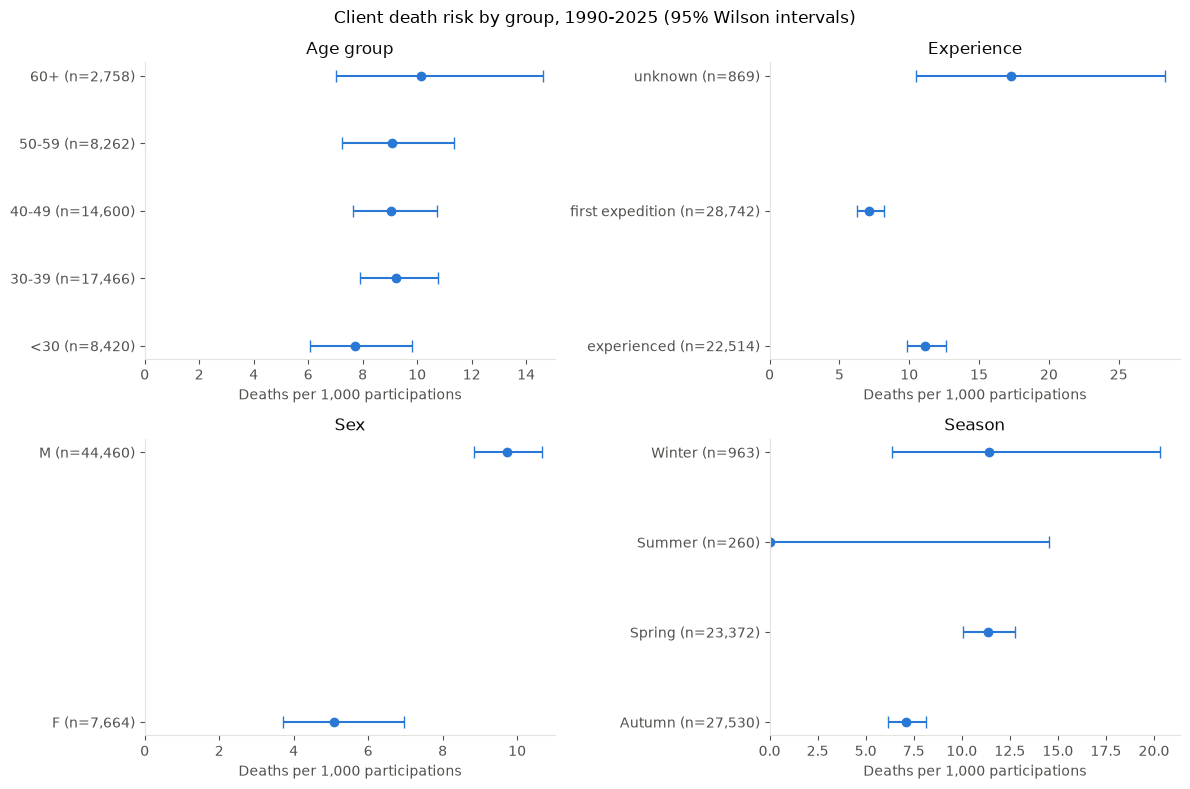

In [3]:
clients = features.assign(AGE_GROUP=age_group(features["CALCAGE"]),
                          EXPERIENCE=experience_group(features["PRIOR_EXPEDITIONS"]),
                          SEASON_NAME=features["SEASON"].map(season_names))
print(f"Clients 1990-2025: {len(clients):,}, deaths: {clients['DEATH'].sum():,} "
      f"({1000 * clients['DEATH'].mean():.1f} per 1,000)")

panels = {"Age group": "AGE_GROUP", "Experience": "EXPERIENCE", "Sex": "SEX", "Season": "SEASON_NAME"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, column) in zip(axes.flat, panels.items()):
    table = member_rates(clients, column)
    print(f"\n{title}:\n{table.round(2).to_string()}")
    y = np.arange(len(table))
    ax.errorbar(table["per_1000"], y, xerr=[table["per_1000"] - table["low"], table["high"] - table["per_1000"]],
                fmt="o", capsize=4, color=BLUE)
    ax.set_yticks(y, [f"{label} (n={n:,})" for label, n in zip(table.index.astype(str), table["n"])])
    ax.set_xlim(left=0)
    ax.set_title(title)
    ax.set_xlabel("Deaths per 1,000 participations")
fig.suptitle("Client death risk by group, 1990-2025 (95% Wilson intervals)")
fig.tight_layout()
save_figure(fig, "06_death_by_group.png")
plt.show()

            deaths      n  per_1000    low   high
PEAK_GROUP                                       
DHA1            45   1691     26.61  19.95  35.42
KANG            23    871     26.41  17.66  39.31
LANG             3    125     24.00   8.20  68.19
ANN1            23    998     23.05  15.41  34.34
MAKA            25   1529     16.35  11.10  24.03
DORJ             2    124     16.13   4.43  56.90
PUMO            18   1199     15.01   9.52  23.61
TILI             5    398     12.56   5.38  29.07
EVER           142  12654     11.22   9.53  13.21
MANA            51   4556     11.19   8.52  14.69
OTHER           59   5413     10.90   8.46  14.03
LHOT            13   1868      6.96   4.07  11.87
ANN4             3    452      6.64   2.26  19.33
CHOY            31   6683      4.64   3.27   6.58
AMAD            23   9099      2.53   1.69   3.79
BARU             3   1714      1.75   0.60   5.13
HIML             2   1811      1.10   0.30   4.02
TUKU             0    217      0.00   0.00  17.40


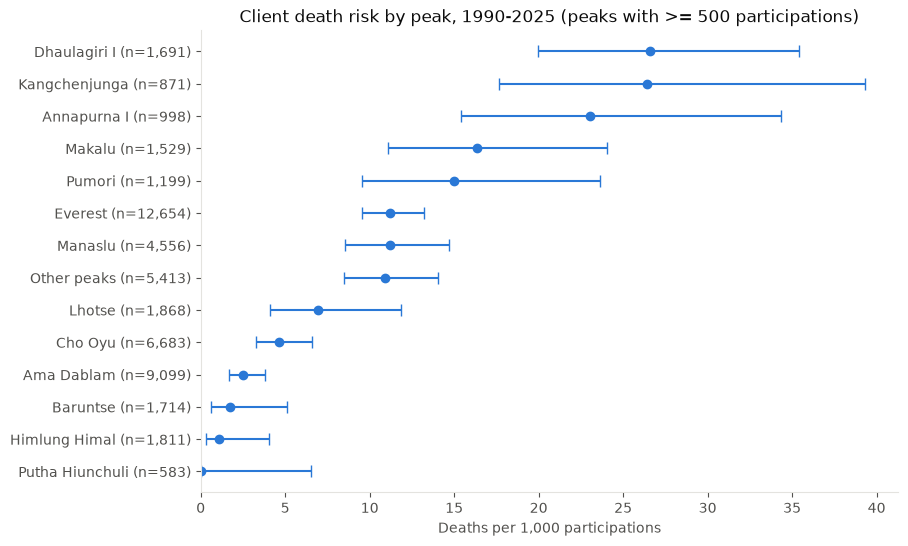

In [4]:
MIN_PARTICIPATIONS = 500
by_peak = member_rates(clients, "PEAK_GROUP").sort_values("per_1000")
print(by_peak.sort_values("per_1000", ascending=False).round(2).to_string())
shown = by_peak[by_peak["n"] >= MIN_PARTICIPATIONS]

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(shown))
ax.errorbar(shown["per_1000"], y, xerr=[shown["per_1000"] - shown["low"], shown["high"] - shown["per_1000"]],
            fmt="o", capsize=4, color=BLUE)
ax.set_yticks(y, [f"{peak_names.get(p, 'Other peaks')} (n={n:,})" for p, n in zip(shown.index, shown["n"])])
ax.set_xlim(left=0)
ax.set_xlabel("Deaths per 1,000 participations")
ax.set_title(f"Client death risk by peak, 1990-2025 (peaks with >= {MIN_PARTICIPATIONS} participations)")
save_figure(fig, "06_death_by_peak.png")
plt.show()

## 3. Clients versus hired staff

We only use expeditions that have both clients and hired staff above base camp, so both groups are on the same peaks in the same years. The risk ratio is the hired rate divided by the client rate, and its 95% interval comes from a bootstrap over whole expeditions (500 samples).

Shared expeditions: 7,707
Risk ratio hired / clients, 1950-2025: 0.68 (95% CI 0.56-0.81)



By decade:
        client_deaths  client_n  client_per_1000  hired_deaths  hired_n  hired_per_1000  ratio  ratio_low  ratio_high
DECADE                                                                                                               
1950               15       483            31.06             9      716           12.57   0.40       0.13        0.83
1960               22       694            31.70             9      953            9.44   0.30       0.12        0.66
1970               74      2537            29.17            51     2180           23.39   0.80       0.44        1.18
1980              134      5862            22.86            45     3033           14.84   0.65       0.42        0.90
1990               91      7301            12.46            46     3973           11.58   0.93       0.61        1.39
2000               88     11616             7.58            50     7161            6.98   0.92       0.52        1.44
2010               90     12878             

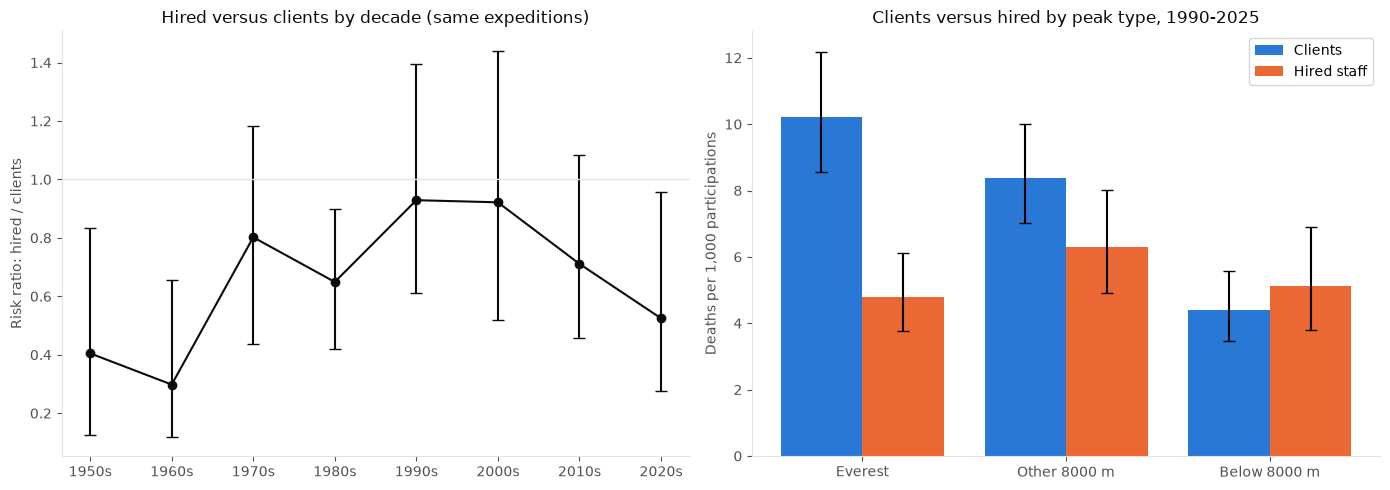

In [5]:
shared = shared_expeditions(counts)
ratio, low, high = risk_ratio_interval(shared)
print(f"Shared expeditions: {len(shared):,}")
print(f"Risk ratio hired / clients, {TREND_YEARS[0]}-{TREND_YEARS[1]}: {ratio:.2f} (95% CI {low:.2f}-{high:.2f})")

columns = ["client_deaths", "client_n", "client_per_1000", "hired_deaths", "hired_n", "hired_per_1000", "ratio", "ratio_low", "ratio_high"]
by_decade = compare_clients_hired(shared, "DECADE")
by_type = compare_clients_hired(shared[shared["YEAR"] >= 1990], "PEAK_TYPE").reindex(["Everest", "Other 8000 m", "Below 8000 m"])
print("\nBy decade:\n" + by_decade[columns].round(2).to_string())
print("\nBy peak type, 1990-2025:\n" + by_type[columns].round(2).to_string())

fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5))
x = by_decade.index.to_numpy()
left.errorbar(x, by_decade["ratio"], yerr=[by_decade["ratio"] - by_decade["ratio_low"], by_decade["ratio_high"] - by_decade["ratio"]],
              marker="o", capsize=4, color=INK)
left.axhline(1, color=GRID, lw=1)
left.set_xticks(x, [f"{d}s" for d in x])
left.set_ylabel("Risk ratio: hired / clients")
left.set_title("Hired versus clients by decade (same expeditions)")

positions = np.arange(len(by_type))
for offset, who, color, label in [(-0.2, "client", BLUE, "Clients"), (0.2, "hired", ORANGE, "Hired staff")]:
    rate = by_type[f"{who}_per_1000"]
    right.bar(positions + offset, rate, width=0.4, color=color, label=label,
              yerr=[rate - by_type[f"{who}_low"], by_type[f"{who}_high"] - rate], capsize=4)
right.set_xticks(positions, by_type.index)
right.set_ylabel("Deaths per 1,000 participations")
right.set_title("Clients versus hired by peak type, 1990-2025")
right.legend()
fig.tight_layout()
save_figure(fig, "06_clients_vs_hired.png")
plt.show()

## 4. When deaths happen

Share of all deaths by phase (`DEATHCLASS`) for clients and hired staff, 1950-2025. Deaths of hired staff are complete in `members`, since they always get a record when they die.

WHO                         Clients  Hired
PHASE                                     
Other / Unknown                 0.5    0.0
Expedition evacuation           4.2    3.1
Ascending in summit bid        13.5    4.3
Death enroute BC                3.7   12.0
Descending from summit bid     36.8   13.3
Death at BC / ABC               4.4   17.0
Route preparation              37.0   50.3


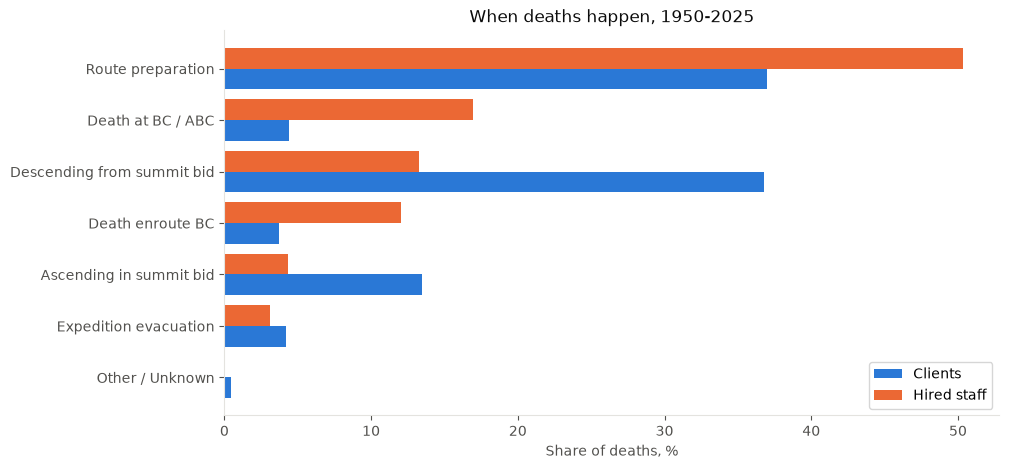

In [6]:
phases = death_class_shares(members).sort_values("Hired")
print(phases.round(1).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(phases))
ax.barh(y - 0.2, phases["Clients"], height=0.4, color=BLUE, label="Clients")
ax.barh(y + 0.2, phases["Hired"], height=0.4, color=ORANGE, label="Hired staff")
ax.set_yticks(y, phases.index)
ax.set_xlabel("Share of deaths, %")
ax.set_title("When deaths happen, 1950-2025")
ax.legend()
save_figure(fig, "06_death_phase.png")
plt.show()